# Noise rejection vs stiffness `k`

Analysis of `std_0.08_k15_to_55.npz` — output of `test_disturbance_no_snapback.py` driven by `GUI_MultiVMC_Noisy_Torque.py` with `PERTURB_STD = 0.08 N·m` added to every motor every control tick.

**Test sequence** (per k = 15, 25, 35, 45, 55):
1. HOMING (k = 200) — initial snap to x = 0
2. MOVING_OUT — ref steps from 0 → -25 cm at current k
3. MOVING_BACK — ref steps back from -25 cm → 0
4. HOLD_AT_ZERO — ref held at 0 for ~2 s at the new k
5. k += 10, repeat

We use these phases to quantify two things:
- **Tracking error** while the ref is moving (MOVING_OUT / MOVING_BACK)
- **Noise-only position fluctuation** — residual after removing the smooth tracking response, attributable purely to the injected noise

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# NPZ = 'std_0.08_k15_to_55.npz'
NPZ = 'std_0.12_k15_to_75.npz'

d = np.load(NPZ)
t        = d['t']
goal_x   = d['goal'][:, 0, 0]      # ref x for VC0 (linear spring)
pos_x    = d['comp_pos'][:, 0, 0]  # FK x for VC0
k_t      = d['k_params'][:, 0]     # k value over time
tau      = d['tau']                # (n, 9) commanded torque (without noise)
perturb  = d['perturb']            # (n, 9) injected Gaussian noise
fs       = float(d['control_freq'][0])

PERTURB_STD = float(perturb.std())   # measured directly from data

print(f'Duration: {t[-1]-t[0]:.1f} s   n = {len(t)}   control_freq = {fs:.0f} Hz')
print(f'k unique: {np.unique(np.round(k_t, 1))}')
print(f'goal_x range: [{goal_x.min():.3f}, {goal_x.max():.3f}] m')
print(f'pos_x  range: [{pos_x.min():.3f},  {pos_x.max():.3f}] m')
print(f'injected noise σ (measured): {PERTURB_STD:.4f} N·m')
print(f'per-motor σ: {perturb.std(axis=0)}')

Duration: 712.2 s   n = 234890   control_freq = 330 Hz
k unique: [ 15.  25.  35.  45.  55. 200.]
goal_x range: [-0.250, 0.000] m
pos_x  range: [-0.165,  0.002] m
injected noise σ (measured): 0.0799 N·m
per-motor σ: [0.08001113 0.07998259 0.07975215 0.07988766 0.07991518 0.08003339
 0.07978815 0.07990203 0.07992938]


In [2]:
# ── numpy-only helpers (no scipy dependency) ─────────────────────────────────

def moving_average(x, win):
    """Centred boxcar smoothing using cumulative-sum trick. O(n)."""
    win = max(3, int(win))
    if win % 2 == 0:
        win += 1
    pad = win // 2
    xp = np.pad(x, pad, mode='edge')
    c  = np.cumsum(np.insert(xp, 0, 0.0))
    return (c[win:] - c[:-win]) / win

def smooth(x, window_s=0.3):
    """Smooth at the deterministic-response timescale (~0.3 s by default)."""
    return moving_average(x, int(window_s * fs))

def welch_psd(x, fs, nperseg=4096):
    """Simple Welch's method (Hann window, 50% overlap, no scipy needed)."""
    n = len(x)
    nperseg = min(nperseg, n)
    step    = nperseg // 2
    win     = np.hanning(nperseg)
    U       = (win**2).sum()                        # window normalisation
    nfreq   = nperseg // 2 + 1
    Pxx     = np.zeros(nfreq)
    n_segs  = 0
    for i in range(0, n - nperseg + 1, step):
        seg = (x[i:i + nperseg] - x[i:i + nperseg].mean()) * win
        F   = np.fft.rfft(seg)
        Pxx += (np.abs(F) ** 2) / (fs * U)
        n_segs += 1
    Pxx /= max(1, n_segs)
    # one-sided correction (double all but DC and Nyquist)
    Pxx[1:-1] *= 2.0
    f = np.fft.rfftfreq(nperseg, d=1.0/fs)
    return f, Pxx

## 1. Time-series overview
Reference vs actual position, with k shown underneath. The K_HOME = 200 segment at the start is shaded grey.

In [3]:
# Detect contiguous segments where k is constant
changes = np.where(np.diff(k_t) != 0)[0] + 1
starts  = np.concatenate([[0], changes])
ends    = np.concatenate([changes, [len(k_t)]])
segs    = [(s, e, float(k_t[s])) for s, e in zip(starts, ends)]
sweep_segs = [seg for seg in segs if seg[2] < 100]  # exclude k_home=200
k_values   = sorted({seg[2] for seg in sweep_segs})
print('Segments:')
for s, e, k in segs:
    print(f'  k = {k:>6.1f}   t = [{t[s]:6.2f}, {t[e-1]:6.2f}] s   n = {e-s}')
print('\nSweep k values:', k_values)

Segments:
  k =  200.0   t = [  0.00,   8.00] s   n = 2641
  k =   15.0   t = [  8.00,  58.20] s   n = 16566
  k =   25.0   t = [ 58.20, 110.40] s   n = 17203
  k =   35.0   t = [110.40, 162.60] s   n = 17226
  k =   45.0   t = [162.60, 214.80] s   n = 17226
  k =   55.0   t = [214.80, 712.16] s   n = 164028

Sweep k values: [15.0, 25.0, 35.0, 45.0, 55.0]


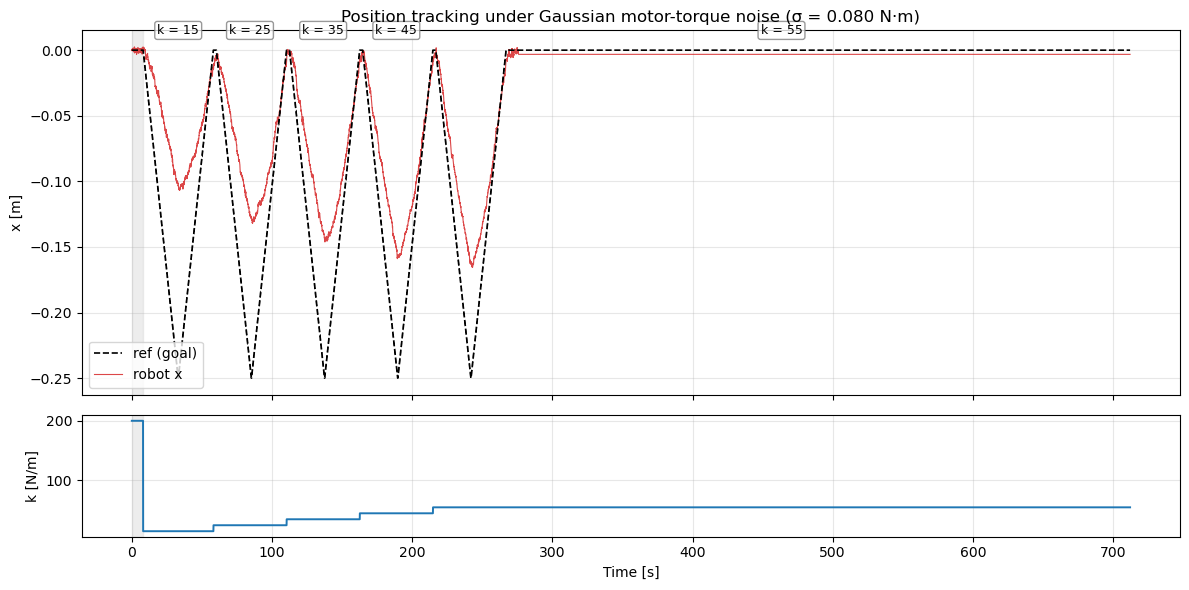

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(12, 6),
                                gridspec_kw={'height_ratios': [3, 1]})

# Shade k=200 (home) segment
for s, e, k in segs:
    if k > 100:
        ax1.axvspan(t[s], t[e-1], color='lightgray', alpha=0.4, zorder=0)
        ax2.axvspan(t[s], t[e-1], color='lightgray', alpha=0.4, zorder=0)

ax1.plot(t, goal_x, '--', color='black', linewidth=1.2, label='ref (goal)', zorder=3)
ax1.plot(t, pos_x,  '-',  color='tab:red', linewidth=0.8, alpha=0.85, label='robot x', zorder=2)
ax1.set_ylabel('x [m]')
ax1.set_title(f'Position tracking under Gaussian motor-torque noise (σ = {PERTURB_STD:.3f} N·m)')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left')

for s, e, k in sweep_segs:
    ax1.text(0.5*(t[s]+t[e-1]), 0.02, f'k = {k:.0f}',
             ha='center', va='top', fontsize=9,
             bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='gray'))

ax2.plot(t, k_t, color='tab:blue', linewidth=1.4)
ax2.set_ylabel('k [N/m]')
ax2.set_xlabel('Time [s]')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Per-k tracking — side-by-side
Each panel zooms into one constant-k cycle. Dashed line = reference; solid red = actual robot position. The visible "fuzz" on the red line is the noise-driven jitter.

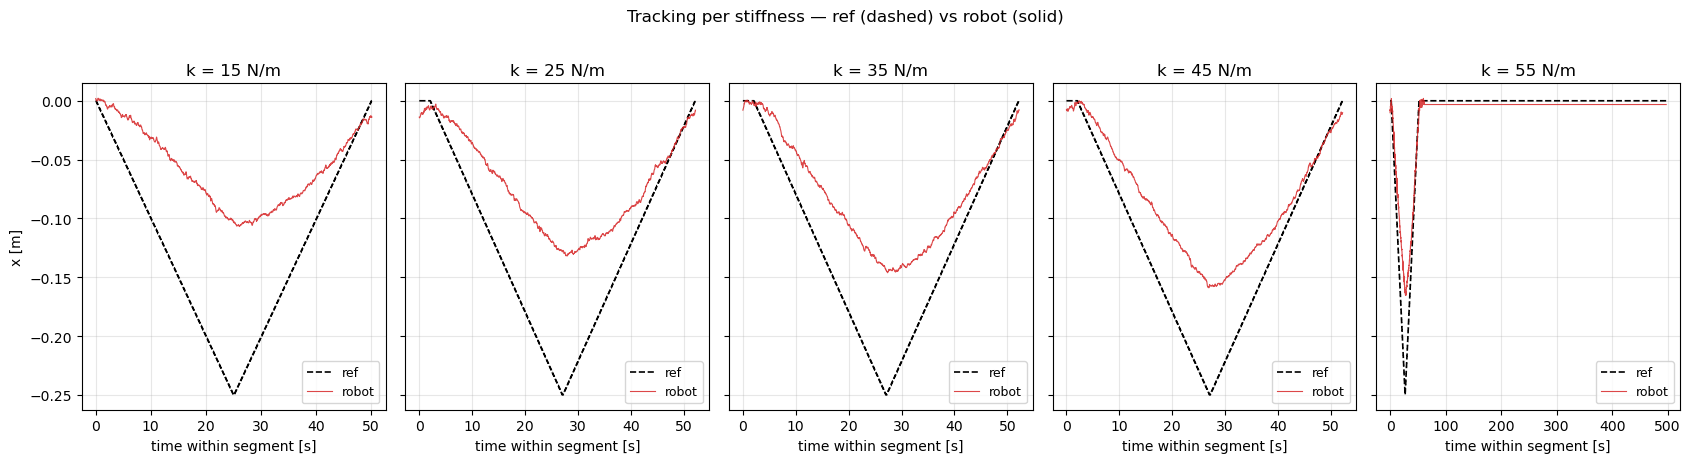

In [5]:
n_k  = len(k_values)
fig, axes = plt.subplots(1, n_k, figsize=(3.4 * n_k, 4.5), sharey=True)
if n_k == 1:
    axes = [axes]

for ax, k in zip(axes, k_values):
    seg = [s for s in sweep_segs if s[2] == k][0]
    s, e, _ = seg
    t_loc = t[s:e] - t[s]
    ax.plot(t_loc, goal_x[s:e], '--', color='black', linewidth=1.2, label='ref')
    ax.plot(t_loc, pos_x[s:e],  '-',  color='tab:red', linewidth=0.8, alpha=0.85, label='robot')
    ax.set_title(f'k = {k:.0f} N/m')
    ax.set_xlabel('time within segment [s]')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='lower right', fontsize=9)
axes[0].set_ylabel('x [m]')
plt.suptitle('Tracking per stiffness — ref (dashed) vs robot (solid)', y=1.02)
plt.tight_layout()
plt.show()

## 3. Quantitative metrics

For each k we compute:

| Metric | What it measures |
|---|---|
| **RMS tracking error** | Total error (bias + noise) while the ref is moving. Static spring offset error $\Delta x = F_{ext}/k$ shows up here. |
| **Mean \|error\|** | Same as RMS but L1 — less sensitive to spikes. |
| **Position-noise σ** | Position fluctuation attributable to noise only (deterministic tracking response removed via moving-average smoothing). This is the cleanest noise-rejection metric. |
| **τ_cmd σ** | Std of the controller's commanded torque — how hard the controller is fighting to compensate for noise. |
| **Effective compliance** | `pos_noise_σ / perturb_σ` (mm per N·m of injected torque noise). Lower = better rejection. |

A stiffer spring should give smaller position-noise σ (better rejection) at the cost of higher τ_cmd σ (more controller effort).

In [6]:
metrics = []
for k in k_values:
    s, e, _ = [seg for seg in sweep_segs if seg[2] == k][0]
    err     = goal_x[s:e] - pos_x[s:e]
    pos_lp  = smooth(pos_x[s:e])
    resid   = pos_x[s:e] - pos_lp                       # noise-only position component
    tau_seg = tau[s:e]
    perturb_seg_std = float(perturb[s:e].std())

    metrics.append({
        'k':              k,
        'rms_error':      float(np.sqrt(np.mean(err**2))),
        'mean_abs_err':   float(np.mean(np.abs(err))),
        'pos_resid_std':  float(np.std(resid)),
        'tau_std':        float(np.mean(tau_seg.std(axis=0))),
        'perturb_std':    perturb_seg_std,
        'compliance':     float(np.std(resid) / perturb_seg_std),
        'n':              int(e - s),
    })

print(f'{"k":>6} | {"RMS err [mm]":>12} | {"|err| [mm]":>11} | {"pos noise σ [mm]":>17} | {"τ σ [N·m]":>10} | {"compl [mm/N·m]":>15}')
print('-'*92)
for m in metrics:
    print(f"{m['k']:>6.0f} | {1000*m['rms_error']:>12.2f} | {1000*m['mean_abs_err']:>11.2f} | "
          f"{1000*m['pos_resid_std']:>17.3f} | {m['tau_std']:>10.4f} | {1000*m['compliance']:>15.3f}")

     k | RMS err [mm] |  |err| [mm] |  pos noise σ [mm] |  τ σ [N·m] |  compl [mm/N·m]
--------------------------------------------------------------------------------------------
    15 |        80.67 |       68.00 |             0.459 |     0.0060 |           5.744
    25 |        61.91 |       50.14 |             0.474 |     0.0071 |           5.932
    35 |        52.71 |       42.59 |             0.472 |     0.0077 |           5.897
    45 |        45.97 |       36.72 |             0.450 |     0.0081 |           5.624
    55 |        13.90 |        6.34 |             0.164 |     0.0041 |           2.057


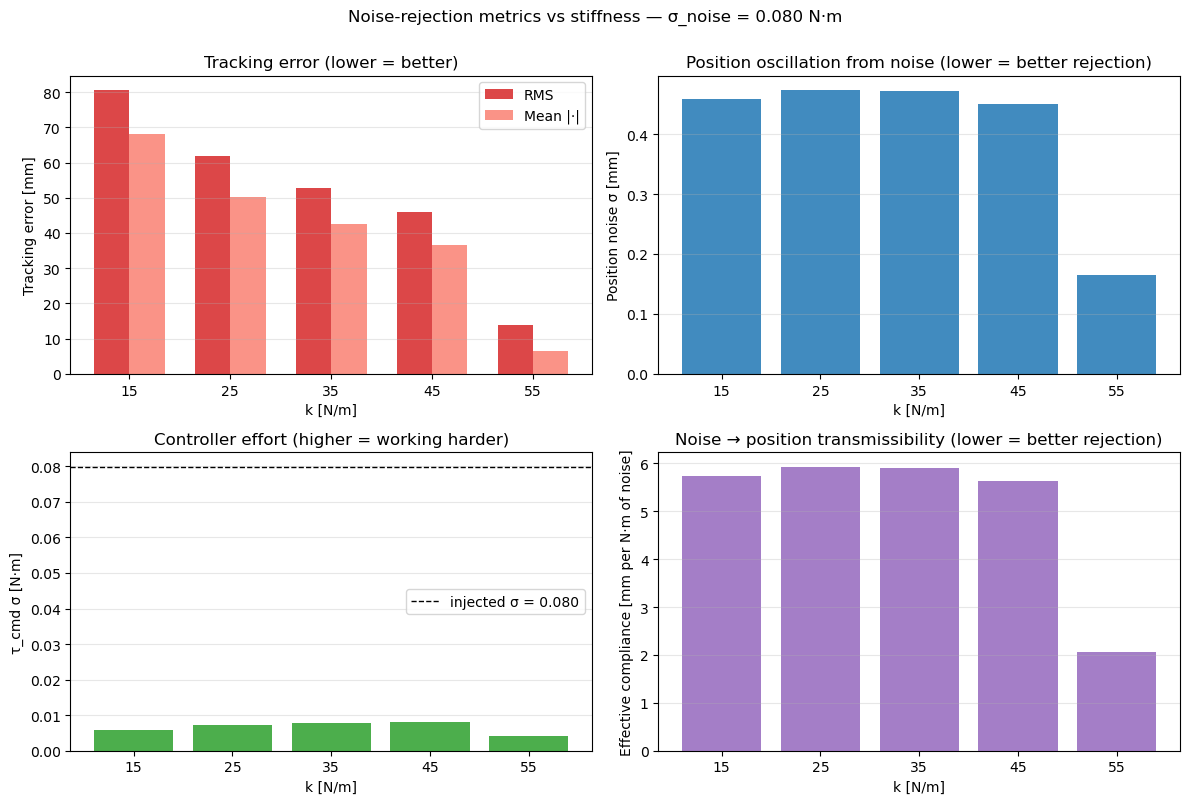

In [7]:
ks    = np.array([m['k'] for m in metrics])
rms   = 1000 * np.array([m['rms_error']     for m in metrics])
mae   = 1000 * np.array([m['mean_abs_err']  for m in metrics])
res   = 1000 * np.array([m['pos_resid_std'] for m in metrics])
tstd  = np.array([m['tau_std']              for m in metrics])
compl = 1000 * np.array([m['compliance']    for m in metrics])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
bw = 0.35
xs = np.arange(len(ks))
xticks = [f'{k:.0f}' for k in ks]

axes[0, 0].bar(xs - bw/2, rms, bw, label='RMS', color='tab:red',  alpha=0.85)
axes[0, 0].bar(xs + bw/2, mae, bw, label='Mean |·|', color='salmon', alpha=0.85)
axes[0, 0].set_xticks(xs); axes[0, 0].set_xticklabels(xticks)
axes[0, 0].set_xlabel('k [N/m]'); axes[0, 0].set_ylabel('Tracking error [mm]')
axes[0, 0].set_title('Tracking error (lower = better)')
axes[0, 0].grid(True, axis='y', alpha=0.3); axes[0, 0].legend()

axes[0, 1].bar(xs, res, color='tab:blue', alpha=0.85)
axes[0, 1].set_xticks(xs); axes[0, 1].set_xticklabels(xticks)
axes[0, 1].set_xlabel('k [N/m]'); axes[0, 1].set_ylabel('Position noise σ [mm]')
axes[0, 1].set_title('Position oscillation from noise (lower = better rejection)')
axes[0, 1].grid(True, axis='y', alpha=0.3)

axes[1, 0].bar(xs, tstd, color='tab:green', alpha=0.85)
axes[1, 0].axhline(PERTURB_STD, color='black', linestyle='--', linewidth=1,
                   label=f'injected σ = {PERTURB_STD:.3f}')
axes[1, 0].set_xticks(xs); axes[1, 0].set_xticklabels(xticks)
axes[1, 0].set_xlabel('k [N/m]'); axes[1, 0].set_ylabel('τ_cmd σ [N·m]')
axes[1, 0].set_title('Controller effort (higher = working harder)')
axes[1, 0].grid(True, axis='y', alpha=0.3); axes[1, 0].legend()

axes[1, 1].bar(xs, compl, color='tab:purple', alpha=0.85)
axes[1, 1].set_xticks(xs); axes[1, 1].set_xticklabels(xticks)
axes[1, 1].set_xlabel('k [N/m]'); axes[1, 1].set_ylabel('Effective compliance [mm per N·m of noise]')
axes[1, 1].set_title('Noise → position transmissibility (lower = better rejection)')
axes[1, 1].grid(True, axis='y', alpha=0.3)

plt.suptitle(f'Noise-rejection metrics vs stiffness — σ_noise = {PERTURB_STD:.3f} N·m', y=1.00, fontsize=12)
plt.tight_layout()
plt.show()

## 4. Tracking error trace per k (overlay)
Aligns the error signals from each k cycle on the same time axis (zero = start of segment) and overlays them. The bigger the visible envelope, the worse the rejection.

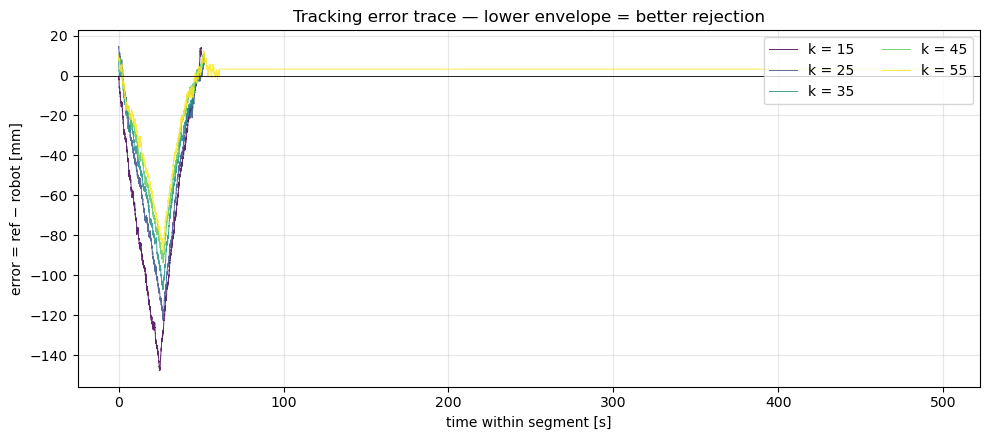

In [8]:
cmap = plt.colormaps['viridis']
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, k in enumerate(k_values):
    s, e, _ = [seg for seg in sweep_segs if seg[2] == k][0]
    t_loc = t[s:e] - t[s]
    err   = goal_x[s:e] - pos_x[s:e]
    color = cmap(i / max(1, len(k_values) - 1))
    ax.plot(t_loc, 1000 * err, color=color, linewidth=0.7, alpha=0.85, label=f'k = {k:.0f}')
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xlabel('time within segment [s]')
ax.set_ylabel('error = ref − robot [mm]')
ax.set_title('Tracking error trace — lower envelope = better rejection')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', ncol=2)
plt.tight_layout()
plt.show()

## 5. Spectral analysis — torque noise → position noise

**Left:** PSD of one motor's injected torque noise. White Gaussian noise should be flat (constant) across all frequencies up to fs/2 — this is a sanity check that the injection is what we think it is.

**Right:** PSD of the position residual (smoothed tracking response removed). This shows where the noise-driven position fluctuation lives in frequency. Higher k pushes the closed-loop bandwidth up, attenuating low-frequency noise but possibly amplifying near the closed-loop resonance.

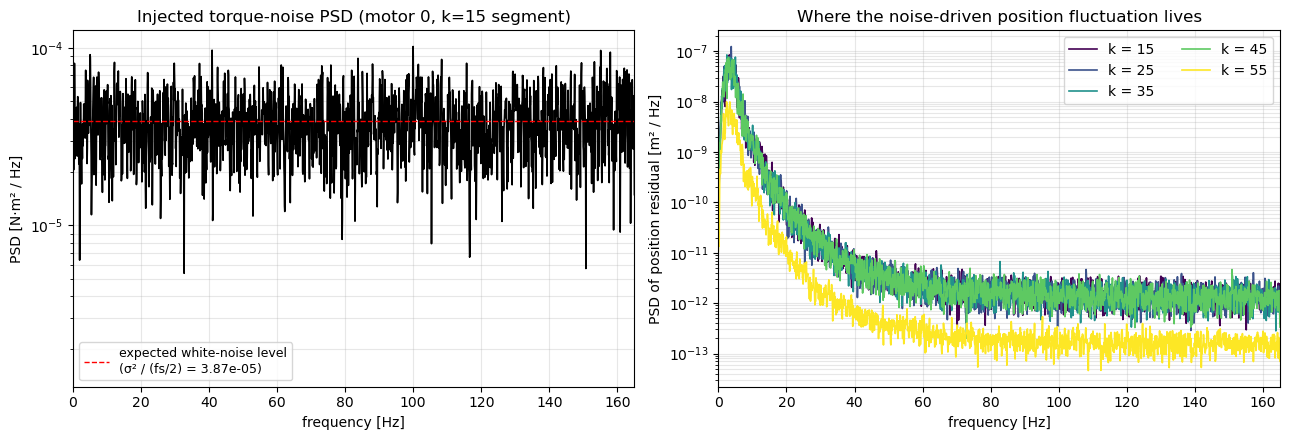

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: injected noise PSD (use first sweep segment)
s, e, _ = sweep_segs[0]
f, P = welch_psd(perturb[s:e, 0], fs=fs, nperseg=4096)
axes[0].semilogy(f, P, color='black', linewidth=1.2)
axes[0].axhline(PERTURB_STD**2 / (fs/2), color='red', linestyle='--', linewidth=1,
                label=f'expected white-noise level\n(σ² / (fs/2) = {PERTURB_STD**2/(fs/2):.2e})')
axes[0].set_xlabel('frequency [Hz]')
axes[0].set_ylabel('PSD [N·m² / Hz]')
axes[0].set_title('Injected torque-noise PSD (motor 0, k=15 segment)')
axes[0].grid(True, which='both', alpha=0.3)
axes[0].set_xlim(0, fs/2)
axes[0].legend(fontsize=9)

# Right: position residual PSD per k
for i, k in enumerate(k_values):
    s, e, _ = [seg for seg in sweep_segs if seg[2] == k][0]
    resid = pos_x[s:e] - smooth(pos_x[s:e])
    f, P = welch_psd(resid, fs=fs, nperseg=4096)
    color = cmap(i / max(1, len(k_values) - 1))
    axes[1].semilogy(f, P, color=color, linewidth=1.2, label=f'k = {k:.0f}')
axes[1].set_xlabel('frequency [Hz]')
axes[1].set_ylabel('PSD of position residual [m² / Hz]')
axes[1].set_title('Where the noise-driven position fluctuation lives')
axes[1].grid(True, which='both', alpha=0.3)
axes[1].set_xlim(0, fs/2)
axes[1].legend(ncol=2)

plt.tight_layout()
plt.show()

## Reading the results

- **Tracking error (panel 3, top-left)** — RMS combines (a) a static *spring offset* error `F_load / k` while the ref is far from 0, which gets smaller as k grows, and (b) the noise-driven jitter (next panel). A clean monotonic drop with k is the expected signature of better rejection.
- **Position noise σ (panel 3, top-right)** — the most direct *noise-rejection* metric. We removed the deterministic tracking response via low-pass smoothing, so what remains is purely the noise-induced position fluctuation.
- **τ_cmd σ (panel 3, bottom-left)** — controller effort. A stiffer spring asks the controller to push harder per mm of error, so this grows with k. If it approaches the per-motor limit (`tau_limit / sqrt(9) ≈ 0.13 N·m`), the controller is saturating and rejection plateaus.
- **Effective compliance (panel 3, bottom-right)** — `pos_noise_σ / perturb_σ` in mm per N·m. This is the **closed-loop transmissibility** of torque noise into position noise, normalised by the injected noise. Lower = the system swallows the disturbance better.
- **Spectra (panel 5)** — confirms (a) the injected noise is white (flat PSD), and (b) the position-residual PSD shifts to higher bandwidth as k grows.